
# Datentransformation-Übungsblatt:

**Bearbeitungszeit:** ca. 90 Minuten

## Szenario
Stell dir vor, du arbeitest als Data Analyst bei einem städtischen Fahrradverleih. Das Unternehmen möchte besser verstehen, wie die Fahrräder genutzt werden und welche Faktoren die Nutzung beeinflussen.

Dazu steht dir ein Datensatz mit Informationen zu 1.000 Fahrten zur Verfügung. Er enthält unter anderem Angaben zum Alter der Kund*innen, zum Kundentyp, zur Fahrtdauer, zur gefahrenen Distanz, zum Preis und zur Bewertung der Fahrt. Der Datensatz ist bereits bereinigt, enthält also keine Duplikate und fehlende Werte.

Deine Aufgabe ist es, den Datensatz mithilfe von Visualisierungen zu untersuchen. Dabei analysierst du Verteilungen, vergleichst Gruppen und suchst nach Zusammenhängen zwischen Variablen, um interessante Erkenntnisse über das Nutzungsverhalten der Kundschaft zu gewinnen.

<div style="
    border: 2px solid #4A90E2;
    border-radius: 5px;
    padding: 10px;
    margin: 10px 0;
">

<b> Hinweis:</b><br>

Erstelle jedes Diagramm nach den Best Practices:
1. Faire Skalen verwenden: Säulen- und Balkendiagramme sollten meist bei 0 beginnen, um Unterschiede nicht zu übertreiben.
2. Beschriften: Titel, Achsen und Einheiten machen eine Grafik verständlich.
3. Einfach halten: Wenige Farben, keine unnötigen Effekte und Fokus auf die wichtigste Aussage.
</div>

## Datenwörterbuch
Der Datensatz enthält folgende Spalten:

| Variable | Datentyp | Beschreibung |
|-----------|-----------|-------------|
| **Alter** | Numerisch (diskret) | Alter der Kundin bzw. des Kunden in Jahren |
| **Kundentyp** | Kategorial | Kundentyp des Fahrradverleihs (*Student*, *Premium*, *Standard*) |
| **Geschlecht** | Kategorial | Geschlecht der Kundin bzw. des Kunden (*weiblich*, *männlich*, *divers*) |
| **Startstation** | Kategorial | Verleihstation, an der die Fahrt begonnen wurde |
| **Wochentag** | Kategorial | Wochentag, an dem die Fahrt stattgefunden hat |
| **Fahrtdauer** | Numerisch (kontinuierlich) | Dauer der Fahrt in Minuten |
| **Distanz** | Numerisch (kontinuierlich) | Zurückgelegte Strecke in Kilometern |
| **Bewertung** | Ordinal | Bewertung der Fahrt auf einer Skala von 1 bis 5 Sternen |
| **Anzahl_Fahrten_Monat** | Numerisch (diskret) | Anzahl der Fahrten der Kundin bzw. des Kunden pro Monat |
| **Preis** | Numerisch (kontinuierlich) | Preis der Fahrt in Euro |

**Anmerkung**: Die Variable **Bewertung** ist ordinal skaliert. Das bedeutet, dass die Werte eine natürliche Reihenfolge besitzen (1 Stern < 2 Sterne < 3 Sterne < 4 Sterne < 5 Sterne). Die Abstände zwischen den einzelnen Stufen müssen jedoch nicht gleich groß sein. Daher können Bewertungen sinnvoll geordnet und als Kategorien genutzt und verglichen werden, während die Interpretation von Mittelwerten mit etwas Vorsicht erfolgen sollte.

## Aufgabe 1 – Überblick über die Daten

Bevor du mit der Visualisierung beginnst, solltest du den Datensatz einlesen und dir einen ersten Überblick über die enthaltenen Daten verschaffen. Untersuche dabei, welche Variablen vorhanden sind, welche Datentypen sie besitzen und wie die ersten Zeilen des Datensatzes aussehen.


<details>
  <summary> Hinweis anzeigen</summary>
Nutze die Funktionen `df.read_csv()`, `df.head()` und `df.info()`
</details>

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("Fahrradverleih.csv")
print(df.head())
print(df.info())

   Alter Kundentyp Geschlecht  Startstation Wochentag  Fahrtdauer  Distanz  \
0     54  Standard   männlich  Hauptbahnhof        Fr       29.01     7.48   
1     67   Student   männlich    Wohngebiet        Mo       26.54     5.49   
2     44   Student   männlich    Innenstadt        Di       22.41     6.63   
3     30   Premium   männlich          Park        Fr       35.17     9.02   
4     58   Premium   männlich   Universität        Sa       26.69     4.29   

   Bewertung  Anzahl_Fahrten_Monat  Preis  
0          3                    10   9.57  
1          5                    10   6.03  
2          5                     7   6.66  
3          4                    10   9.25  
4          3                     6   5.88  
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alter                 1000 non-null   int64  
 1   Kundentyp     

## Aufgabe 2 – Wie ist die monatliche Anzahl der Fahrten verteilt?

Untersuche, wie sich die monatliche Anzahl der Fahrten verteilt.

Erstelle eine geeignete Visualisierung und beantworte anschließend folgende Fragen:

> Wie viele Fahrten werden pro Monat typischerweise durchgeführt?
>
> Welche Anzahl an Fahrten kommt besonders häufig vor?
>
> Gibt es Kund*innen mit ungewöhnlich vielen Fahrten?
>
> Ist die Verteilung eher symmetrisch oder schief?


<details>
  <summary> Hinweis anzeigen</summary>

Für die Untersuchung einer Verteilung eignet sich besonders ein Histogramm. Alternativ kannst du zusätzlich einen Boxplot erstellen, um die Verteilung aus einer anderen Perspektive zu betrachten.

* Nutze die Funktion `sns.histplot()` und gib für den Parameter `data` den DataFrame `df` und für den Parameter `x` den Namen der Variable `"Anzahl_Fahrten_Monat"` an.
* Nutze `plt.title()`, um einen aussagekräftigen Titel hinzuzufügen.
* Nutze `plt.ylabel()`, um die y-Achse zu beschriften.

Überlege dir außerdem, woher die Lücken im Diagramm kommen. Die Anzahl an Bins kannst du mit dem Paramter `bin` ändern. Überlege dir eine geeignete Anzahl oder probiere verschiedene aus.

</details>

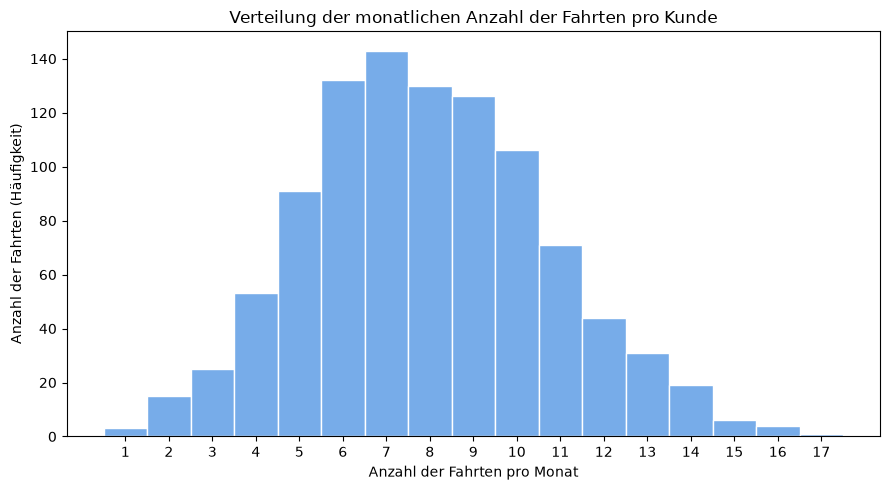

In [2]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="Anzahl_Fahrten_Monat",
    bins=range(1, 19),
    discrete=True,
    color="#4A90E2",
    edgecolor="white"
)
plt.title("Verteilung der monatlichen Anzahl der Fahrten pro Kunde")
plt.xlabel("Anzahl der Fahrten pro Monat")
plt.ylabel("Anzahl der Fahrten (Häufigkeit)")
plt.xticks(range(1, 18))
plt.tight_layout()
plt.show()

## Aufgabe 3 – Gibt es Ausreißer bei der Fahrtdauer?

Untersuche, ob es bei der Fahrtdauer ungewöhnlich kurze oder ungewöhnlich lange Fahrten gibt. Visualisiere die Variable `Fahrtdauer` und prüfe, ob mögliche Ausreißer erkennbar sind.

Beantworte anschließend folgende Fragen:

>Gibt es Fahrten, die deutlich länger oder kürzer dauern als die meisten anderen?
>
> Wie stark streuen die Fahrtdauern?
>
> Wo liegt der typische Bereich der Fahrtdauer?

<details>
  <summary> Hinweis anzeigen</summary>
Ein Boxplot eignet sich besonders gut, um Ausreißer, den Median und die Streuung einer numerischen Variable auf einen Blick zu erkennen.

* Nutze die Funktion `sns.boxplot()`, um einen Boxplot zu erstellen. Überlege dir, was du für `data` und `x` einsetzen musst.
* Nutze `plt.xlabel()`, um die x-Achse zu beschriften. Denke daran, die Einheit hinzuzufügen.
</details>

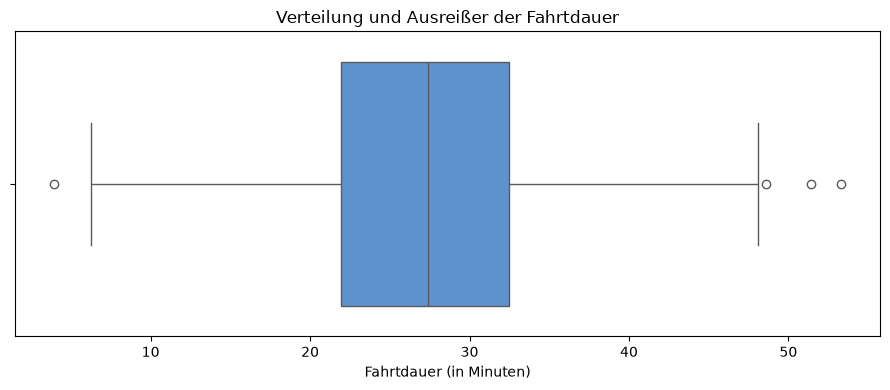

In [3]:
plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x="Fahrtdauer", color="#4A90E2")
plt.title("Verteilung und Ausreißer der Fahrtdauer")
plt.xlabel("Fahrtdauer (in Minuten)")
plt.tight_layout()
plt.show()

## Aufgabe 4 – Welche Startstation wird am häufigsten genutzt?

Untersuche, welche Startstation von den Kund*innen am häufigsten genutzt wird.

Erstelle eine geeignete Visualisierung und beantworte anschließend folgende Fragen:

>Welche Startstation wird am häufigsten bzw. seltensten genutzt?
>
> Sind die Nutzungen der Stationen ähnlich verteilt oder gibt es deutliche Unterschiede?
>
> Welche Erkenntnisse könnte der Fahrradverleih aus diesem Ergebnis ableiten?

<details>
  <summary> Hinweis anzeigen</summary>
Für die Darstellung von Häufigkeiten kategorialer Variablen eignet sich besonders ein Countplot. Er zeigt auf einen Blick, wie oft jede Kategorie im Datensatz vorkommt.

* Nutze `sns.countplot()`, um einen Countplot zu erstellen.

</details>



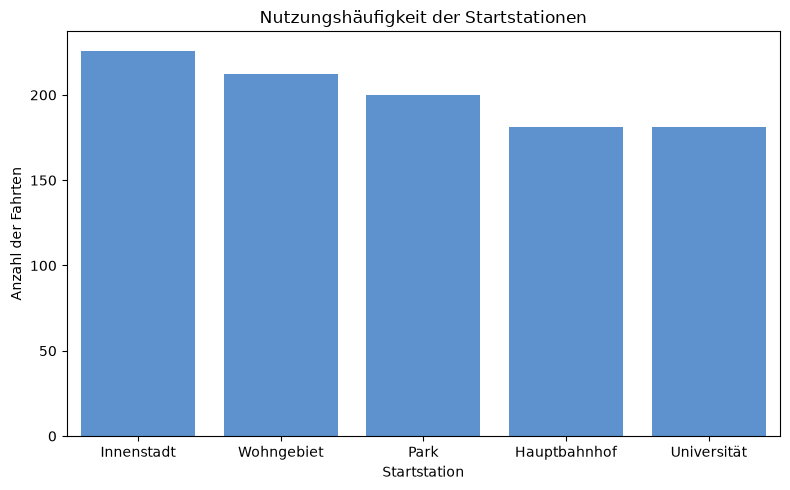

In [4]:
order_stations = df["Startstation"].value_counts().index

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Startstation", order=order_stations, color="#4A90E2")
plt.title("Nutzungshäufigkeit der Startstationen")
plt.xlabel("Startstation")
plt.ylabel("Anzahl der Fahrten")
plt.tight_layout()
plt.show()

**Optional**: Hebe die Säule für die Startstation, die am häufigsten genutzt wird, farblich hervor.

In [ ]:
# Lösung


## Aufgabe 5 – Welcher Kundentyp erzielt den höchsten durchschnittlichen Fahrpreis?

Untersuche, ob sich die durchschnittlichen Fahrpreise zwischen den verschiedenen Kundentypen unterscheiden.

Erstelle eine geeignete Visualisierung und beantworte anschließend folgende Fragen:

>Welcher Kundentyp erzielt den höchsten durchschnittlichen Fahrpreis?
>
> Welcher Kundentyp zahlt im Durchschnitt am wenigsten?
>
> Wie groß sind die Unterschiede zwischen den Kundentypen?
>
> Wodurch könnten diese Unterschiede erklärt werden?

<details>
<summary>Hinweis anzeigen</summary>
Ein Barplot eignet sich besonders gut, um Durchschnittswerte verschiedener Gruppen miteinander zu vergleichen.

* Nutze die Funktion `sns.barplot()` und belege die Argumente `data`, `x` und `y` mit den richtigen Werten.
</details>


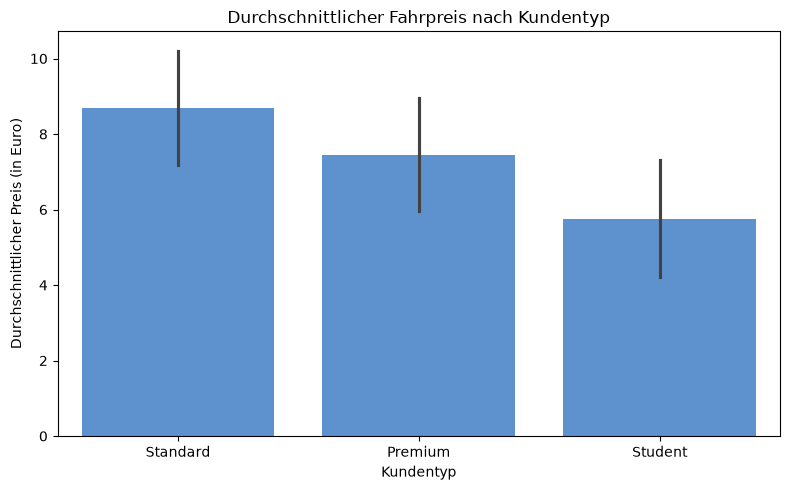

In [5]:
plt.figure(figsize=(8, 5))
sns.barplot(
    data=df,
    x="Kundentyp",
    y="Preis",
    order=["Standard", "Premium", "Student"],
    color="#4A90E2",
    errorbar="sd"
)
plt.title("Durchschnittlicher Fahrpreis nach Kundentyp")
plt.xlabel("Kundentyp")
plt.ylabel("Durchschnittlicher Preis (in Euro)")
plt.tight_layout()
plt.show()

## Aufgabe 6 – Wie verteilen sich die Bewertungen auf die Kundentypen?

Untersuche, wie sich die Bewertungen der Fahrten auf die verschiedenen Kundentypen verteilen.

Erstelle eine geeignete Visualisierung und beantworte anschließend folgende Fragen:

>Welcher Kundentyp vergibt die besten bzw. niedrigsten Bewertungen?
>
> Wie stark unterscheiden sich die Bewertungen zwischen den Kundengruppen?
>
> Gibt es Kundentypen mit besonders vielen hohen oder niedrigen Bewertungen?


<details>
<summary>Hinweis anzeigen</summary>
Ein gruppiertes Säulendiagramm (Countplot mit zusätzlicher Farbe) eignet sich besonders gut, um die Verteilung der Bewertungen zwischen den Kundentypen zu vergleichen. Da es sich bei den Bewertungen um eine ordinale Variable handelt, können wir sie wie geordnete Kategorien behandeln. Alternativ könnte sich ein Barplot eignen, wenn du die durchschnittlichen Bewertungen vergleichen möchtest. Dabei müssen wir bei der Interpretation allerdings vorsichtig sein, da die Abstände zwischen den einzelnen Bewertungskategorien nicht notwendigerweise gleich groß sind.

* Nutze die Funktion `sns.countplot()` und wähle `"Kundentyp"` für `x` und `"Bewertung"` für `hue`.


</details>

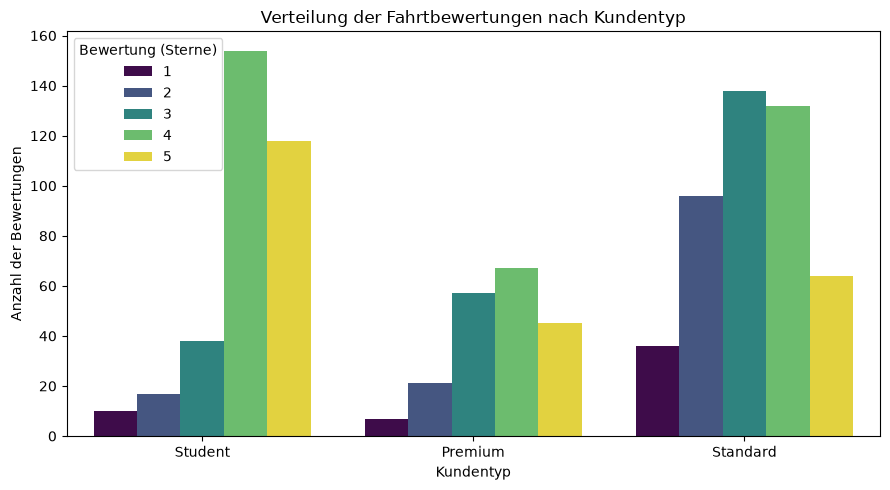

In [6]:
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x="Kundentyp",
    hue="Bewertung",
    order=["Student", "Premium", "Standard"],
    palette="viridis"
)
plt.title("Verteilung der Fahrtbewertungen nach Kundentyp")
plt.xlabel("Kundentyp")
plt.ylabel("Anzahl der Bewertungen")
plt.legend(title="Bewertung (Sterne)")
plt.tight_layout()
plt.show()

## Aufgabe 7 – Welche numerischen Variablen hängen linear miteinander zusammen?

Untersuche, welche numerischen Variablen im Datensatz linear miteinander zusammenhängen.

Berechne zunächst die Korrelationsmatrix und visualisiere diese anschließend mit einer geeigneten Grafik. Analysiere danach die Ergebnisse und beantworte folgende Fragen:

>Welche Variablen weisen die stärksten positiven linearen Zusammenhänge auf?
>
> Gibt es Variablen, die nur schwach oder gar nicht linear zusammenhängen?
>
> Welche (fehlenden) linearen Zusammenhänge überraschen dich?

<details>
<summary>Hinweis anzeigen</summary>
Eine Heatmap zeigt dir auf einen Blick, wie stark die linearen Zusammmenhänge zwischen den numerischen Variablen sind.

* Erstelle zunächst eine Korrelationsmatrix mit `df.select_dtypes(include="number").corr()`
* Erstelle dann daraus eine Heatmap mit `sns.heatmap()`.

Bei der Interpretation der Korrelationswerte helfen folgende Faustregeln:

* 0,00 bis 0,19: kein bzw. sehr schwacher Zusammenhang
* 0,20 bis 0,39: schwacher Zusammenhang
* 0,40 bis 0,59: mittlerer Zusammenhang
* 0,60 bis 0,79: starker Zusammenhang
* 0,80 bis 1,00: sehr starker Zusammenhang

</details>

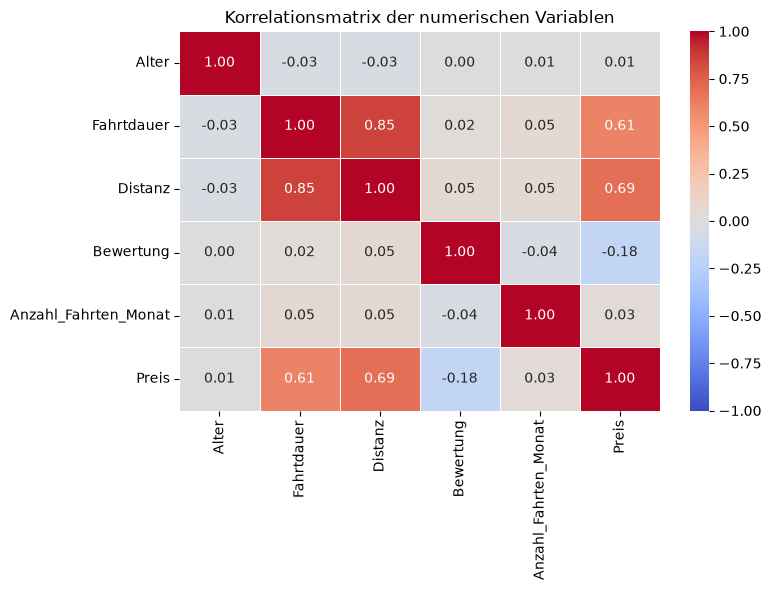

In [7]:
corr_matrix = df.select_dtypes(include="number").corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title("Korrelationsmatrix der numerischen Variablen")
plt.tight_layout()
plt.show()

## Aufgabe 8 – Unterscheidet sich der Zusammenhang zwischen Distanz und Preis nach Kundentyp?

Untersuche, ob sich der Zusammenhang zwischen Distanz und Preis je nach Kundentyp unterscheidet.

Erstelle eine geeignete Visualisierung und analysiere anschließend, ob für die verschiedenen Kundentypen unterschiedliche Muster erkennbar sind.

Beantworte dabei folgende Fragen:

>Steigt der Preis mit zunehmender Distanz?
>
> Ist dieser Zusammenhang bei allen Kundentypen ähnlich?
>
> Gibt es Unterschiede zwischen Studierenden, Premium- und Standardkunden?
>
> Welche Kundengruppe zahlt bei gleicher Distanz tendenziell mehr oder weniger?

<details>

<summary>Hinweis anzeigen</summary>

Ein Scatterplot mit dem Parameter `hue` eignet sich besonders gut, um Zusammenhänge zwischen zwei numerischen Variablen zu untersuchen und gleichzeitig Unterschiede zwischen Gruppen sichtbar zu machen.

* Nutze `sns.scatterplot()`

</details>


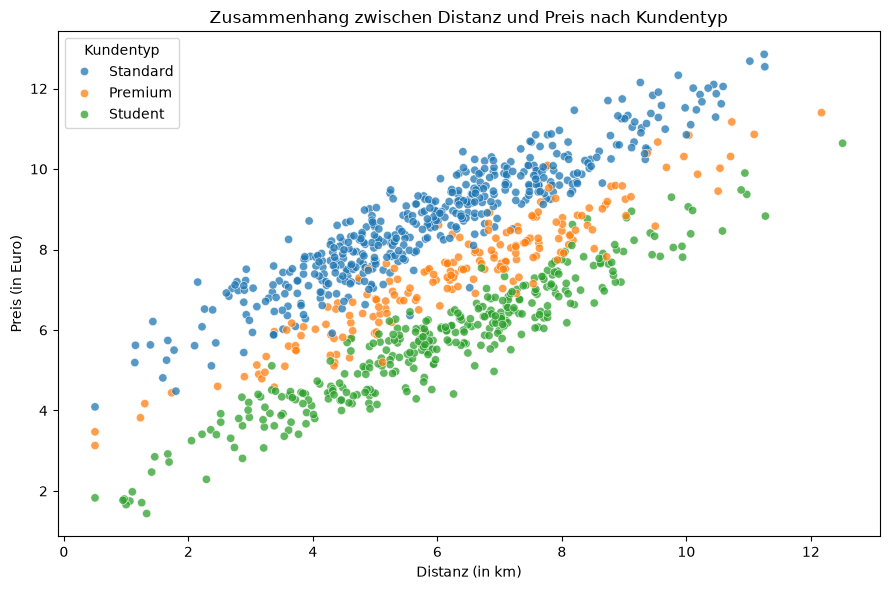

In [8]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="Distanz",
    y="Preis",
    hue="Kundentyp",
    hue_order=["Standard", "Premium", "Student"],
    alpha=0.75
)
plt.title("Zusammenhang zwischen Distanz und Preis nach Kundentyp")
plt.xlabel("Distanz (in km)")
plt.ylabel("Preis (in Euro)")
plt.legend(title="Kundentyp")
plt.tight_layout()
plt.show()

## Aufgabe 9 - Wie unterscheidet sich die Preisverteilung zwischen den Kundentypen?

Untersuche, wie sich die Preisverteilung zwischen den verschiedenen Kundentypen unterscheidet.

Erstelle für jeden Kundentyp ein eigenes Histogramm und vergleiche die Verteilungen miteinander. Die Histogramme sollen nebeneinander dargestellt werden, sodass die Preisverteilungen der einzelnen Kundengruppen direkt verglichen werden können.

Beantworte dabei folgende Fragen:

>Welcher Kundentyp zahlt die höchsten bzw. niedrigsten Preise?
>
> Wie stark streuen die Preise innerhalb der einzelnen Kundengruppen?
>
> Gibt es Ausreißer?
>
> Unterscheiden sich die Preisverteilungen deutlich voneinander?

<details>
<summary>Hinweis anzeigen</summary>
Ein FacetGrid mit Histogrammen eignet sich besonders gut, um Verteilungen verschiedener Gruppen direkt miteinander zu vergleichen, da jede Gruppe ihre eigene Visualisierung erhält.

* Erstelle zunächst ein FacetGrid für die Variable `"Kundentyp"` mit `sns.FacetGrid()` und weise es einer neuen Variable `g` zu.
* Wende auf `g` dann ein Histogramm an für die Variable `"Preis"` mit `g.map(sns.histplot,"Preis")`.
* Passe den Titel mit `g.figure.suptitle()` an und nutze den Parameter `y`, um die Höhe anzupassen.
* Passe die Achsenbeschriftungen an mit `g.set_axis_labels()`.


</details>

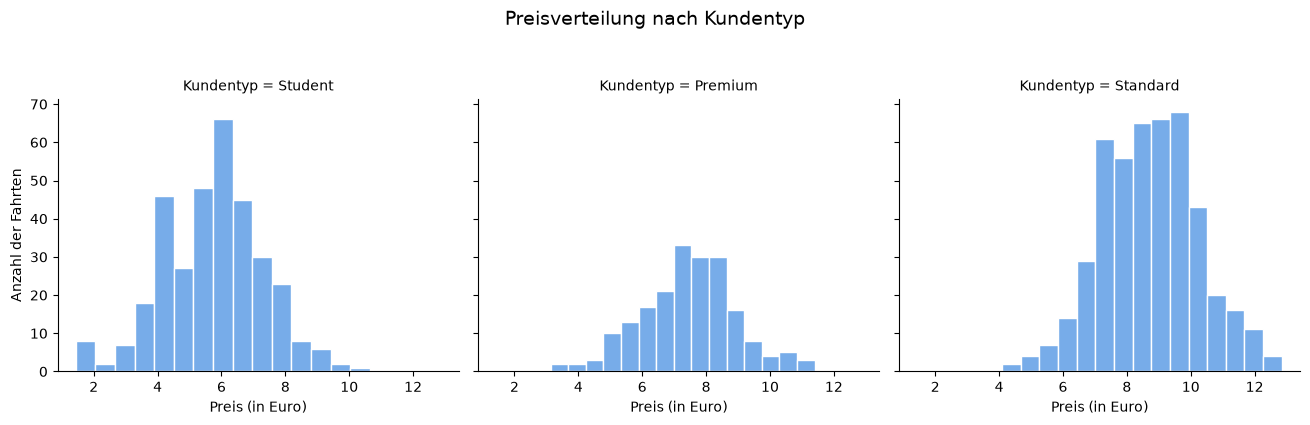

In [9]:
g = sns.FacetGrid(
    df,
    col="Kundentyp",
    col_order=["Student", "Premium", "Standard"],
    height=4,
    aspect=1.1
)
g.map(sns.histplot, "Preis", bins=15, color="#4A90E2", edgecolor="white")
g.figure.suptitle("Preisverteilung nach Kundentyp", y=1.05, fontsize=14)
g.set_axis_labels("Preis (in Euro)", "Anzahl der Fahrten")
plt.tight_layout()
plt.show()

## Aufgabe 10 - An welchen Wochentagen sind die Fahrten am längsten?

Untersuche, an welchen Wochentagen die Fahrten am längsten dauern.

Erstelle eine geeignete Visualisierung und vergleiche die Fahrtdauern der einzelnen Wochentage miteinander.

Beantworte anschließend folgende Fragen:

>An welchem Wochentag ist die typische Fahrtdauer am höchsten bzw. am niedrigsten?
>
> Unterscheiden sich die Fahrtdauern zwischen Werktagen und Wochenende?
>
> Gibt es an einzelnen Tagen besonders lange Fahrten oder Ausreißer?

<details>
<summary>Hinweis anzeigen</summary>
Ein Boxplot eignet sich besonders gut, um die Fahrtdauern verschiedener Wochentage zu vergleichen, da Median, Streuung und mögliche Ausreißer gleichzeitig sichtbar werden.

</details>

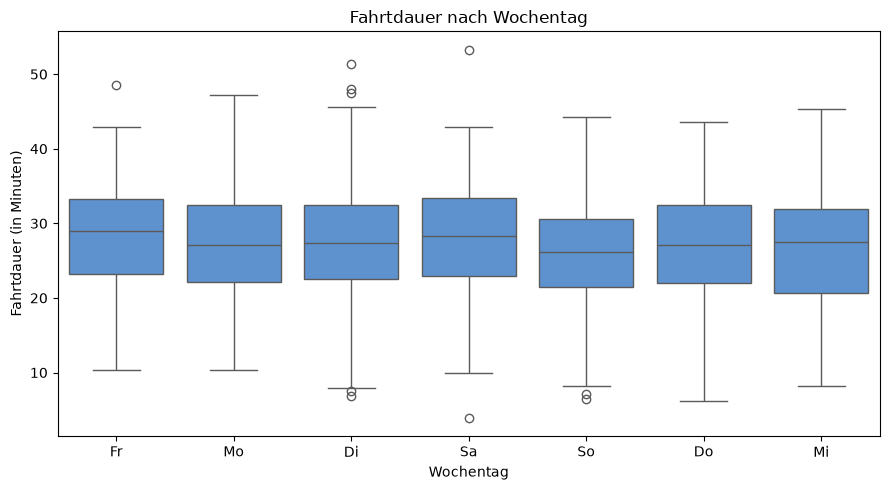

In [10]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Wochentag", y="Fahrtdauer", color="#4A90E2")
plt.title("Fahrtdauer nach Wochentag")
plt.xlabel("Wochentag")
plt.ylabel("Fahrtdauer (in Minuten)")
plt.tight_layout()
plt.show()

**Optional**: Sortiere die Wochentage von Mo bis So. Nutze dafür `pd.Categorical()`.

**Optional**: Färbe die Boxplots für das Wochenende rot ein.

In [ ]:
# Lösung


Du hast nun die wichtigsten Visualisierungen der Explorativen Datenanalyse kennengelernt und auf einen realistischen Datensatz angewendet. Dabei hast du Verteilungen untersucht, Gruppen miteinander verglichen, Zusammenhänge analysiert und sogar mehrere Variablen gleichzeitig betrachtet.

Die hier bearbeiteten Aufgaben stellen nur einen kleinen Ausschnitt der Möglichkeiten dar. Wenn du noch Zeit und Lust hast, formuliere eigene Fragestellungen und überlege, mit welchem Diagrammtyp du diese am besten beantworten kannst. Oft entstehen die spannendsten Erkenntnisse erst durch eigene Analysen und das gezielte Erkunden der Daten. Viel Spaß!